# Medir y corregir aberraciones con el propio SLM: modos de Zernike y recuperación sin sensor

**Pregunta:** ¿Cómo se miden y corrigen con el propio SLM las aberraciones del sistema óptico, y cuán de cerca recupera el frente de onda una búsqueda que solo ve la cámara?

- Nivel: 2, el método en la práctica.
- Requisitos previos: `01-fourier-optics/01-where-the-light-goes` para el campo focal, y `06-device-and-aberrations/01-what-the-device-costs` para la idea de un patrón mostrado que difiere del calculado.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de 40 segundos.

## Objetivos

Los lentes entre el SLM y los átomos o las esferas no son perfectos, y sus errores añaden una fase suave al frente de onda para el que se calculó el holograma. El SLM está en la pupila, de modo que puede restar de nuevo esa fase, si se conoce. Este notebook muestra cómo se describe, cuánto cuesta y cómo se encuentra sin un sensor de frente de onda. Al terminar puedes:

- describir un frente de onda con modos de Zernike en orden de Noll, y comprobar que los modos son ortonormales sobre la pupila;
- convertir una lista de coeficientes en un error rms en ondas y en una primera estimación de la luz que se pierde;
- medir, en este arreglo, cómo cae la luz de las trampas cuando un coeficiente queda mal, y compararlo con la curva de Maréchal;
- ejecutar la búsqueda modal sin sensor de M14 con una cámara ideal y con una ruidosa, y leer cuán de cerca recupera los coeficientes;
- decir qué supone la corrección sobre la aberración.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.camera import EmulatedCamera
from pipeline.model.holo.core.geometry import slm_grid
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.core.zernike import noll_to_nm, rms_waves, strehl, zernike
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.control import m14_zernike

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C09 de `data/examples/cases.json`: 16 trampas en un SLM de 256 x 256 píxeles, y una aberración del sistema dada como coeficientes de Noll en ondas.

- Propietario: este repositorio; el caso es sintético, y su aberración es un modelo declarado, no una medición de un instrumento.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C09.

In [2]:
# caso C09: 16 trampas y una aberración del sistema dada como coeficientes de Noll en ondas
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C09"]
setup = build.setup_of(rec)
target = build.target_of(rec)
coeffs = build.aberration_coeffs(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")
print("aberración (j de Noll: ondas):", rec["aberration"]["noll"])

C09_aberrated | 16 trampas | SLM 256 x 256 píxeles
aberración (j de Noll: ondas): {'4': 0.08, '5': 0.07, '6': 0.05, '7': 0.06, '8': -0.05, '11': 0.04}


## Método

### Paso 1: los modos de Zernike

Un frente de onda suave sobre una pupila redonda se escribe como una suma de modos, $W(\rho, \theta) = \sum_j c_j Z_j(\rho, \theta)$, con $c_j$ en ondas. Los modos $Z_n^m = N_n^m R_n^{|m|}(\rho) \cos(m\theta)$ o $\sin(|m|\theta)$ se indexan con el número único $j$ de Noll (1976), que los ordena por grado radial $n$ y luego por orden angular $m$: $j = 4$ es desenfoque, 5 y 6 son los dos astigmatismos, 7 y 8 coma, 9 y 10 trébol, 11 esférica primaria. El pipeline los normaliza a rms unitario sobre el disco, de modo que son ortonormales, y el error rms del frente de onda es simplemente la raíz de la suma de los coeficientes al cuadrado. La celda evalúa los modos 4 a 11 en la pupila del SLM (un disco inscrito en la malla de píxeles) y calcula sus productos medios, que deben dar la matriz identidad.

In [3]:
# modos de Zernike 4 a 11 en la pupila del SLM, y sus productos medios sobre el disco
x, y = slm_grid(setup)
radius = setup.n_pix * setup.pitch_m / 2
rho, theta = np.hypot(x, y) / radius, np.arctan2(y, x)
js = list(range(4, 12))
modes = np.array([zernike(j, rho, theta) for j in js])
inside = rho <= 1
gram = modes[:, inside] @ modes[:, inside].T / inside.sum()
for k, j in enumerate(js):
    print(f"j = {j:2d}: (n, m) = {noll_to_nm(j)}  media cuadrática sobre el disco {gram[k, k]:.3f}")
print(f"mayor producto entre dos modos distintos: {np.abs(gram - np.diag(np.diag(gram))).max():.4f}")

j =  4: (n, m) = (2, 0)  media cuadrática sobre el disco 1.000
j =  5: (n, m) = (2, -2)  media cuadrática sobre el disco 0.999
j =  6: (n, m) = (2, 2)  media cuadrática sobre el disco 1.001
j =  7: (n, m) = (3, -1)  media cuadrática sobre el disco 1.000
j =  8: (n, m) = (3, 1)  media cuadrática sobre el disco 1.000
j =  9: (n, m) = (3, -3)  media cuadrática sobre el disco 1.000
j = 10: (n, m) = (3, 3)  media cuadrática sobre el disco 1.000
j = 11: (n, m) = (4, 0)  media cuadrática sobre el disco 1.000
mayor producto entre dos modos distintos: 0.0013


Los ocho modos se dibujan como mapas sobre la pupila, con la misma escala de colores.

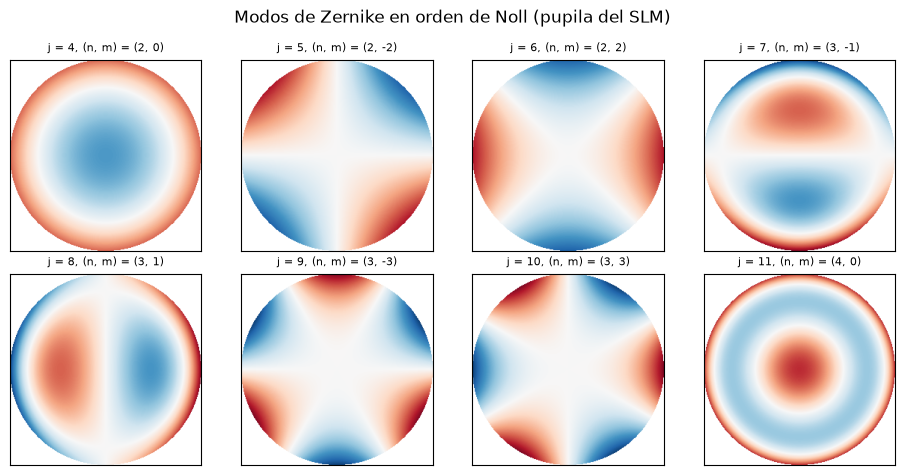

In [4]:
# los ocho modos como mapas sobre la pupila, en ondas por coeficiente unitario
fig, axes = plt.subplots(2, 4, figsize=(9.4, 4.8))
for ax, j, mode in zip(axes.ravel(), js, modes):
    shown = np.where(inside, mode, np.nan)
    ax.imshow(shown, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_title(f"j = {j}, (n, m) = {noll_to_nm(j)}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Modos de Zernike en orden de Noll (pupila del SLM)")
plt.tight_layout()
plt.show()

La tabla muestra qué significa ortonormal en la práctica: cada modo tiene una media cuadrática de 1,000 sobre el disco (0,999 a 1,001, siendo la diferencia la discretización de un disco en 256 x 256 píxeles), y el mayor producto entre dos modos distintos es 0,0013. Los mapas muestran qué le hace cada coeficiente a un frente de onda. El desenfoque es un cuenco, los astigmatismos son sillas a 45 grados entre sí, la coma es una inclinación que se invierte en el centro, el trébol tiene tres lóbulos y la aberración esférica es un cuenco con un anillo. La ortogonalidad es lo que hace posible el paso siguiente, porque los coeficientes se pueden cambiar de a uno sin perturbar a los demás, y hace del error rms una suma de cuadrados. La figura no muestra los modos de orden alto, que no están entre los primeros 21 que lleva el pipeline, ni el pistón, la inclinación en x y la inclinación en y, que mueven las trampas o no las cambian.

### Paso 2: la aberración del caso y lo que cuesta

El caso C09 da seis coeficientes, de 0,04 a 0,08 ondas. Su raíz de la suma de cuadrados es el error rms del frente de onda. La aproximación de Maréchal (Noll 1976 da el rms; la forma exponencial es la estimación estándar para aberraciones pequeñas, y el módulo del pipeline la declara sin verificar contra el artículo) convierte el rms en una razón de Strehl, la fracción de intensidad pico que queda, $S \approx \exp[-(2\pi\sigma_W)^2]$. Está pensada para $\sigma_W$ menor que cerca de $1/14$ de onda. La celda imprime ambos números para el caso.

In [5]:
# la aberración de C09: rms sobre la pupila, y la estimación de Maréchal de la razón de Strehl
sigma_w = rms_waves(coeffs)
print(f"error rms del frente de onda: {sigma_w:.4f} ondas")
print(f"estimación de Maréchal de la razón de Strehl: {strehl(coeffs):.4f}")
print(f"mayor coeficiente: {max(coeffs, key=abs):+.2f} ondas")
print(f"pistón excluido; modos en uso: {[j for j, c in enumerate(coeffs, start=1) if c != 0]}")

error rms del frente de onda: 0.1466 ondas
estimación de Maréchal de la razón de Strehl: 0.4279
mayor coeficiente: +0.08 ondas
pistón excluido; modos en uso: [4, 5, 6, 7, 8, 11]


El frente de onda del caso tiene un rms de 0,1466 ondas, cerca del doble del rango de validez de la estimación, y el Strehl de Maréchal es 0,4279. Para ver qué le hace la aberración a la luz en las trampas, calcula un holograma de GS ponderado para el sistema ideal (M06, 30 iteraciones), y pide a M14 en su modo `correct` que lo muestre a través del sistema aberrado dos veces: una sin restar nada, y otra restando de la fase mostrada los coeficientes exactos, $\phi_\text{shown} = \phi_\text{base} - 2\pi \sum_j \hat c_j Z_j$.

In [6]:
# el holograma calculado para el sistema ideal, y el mismo holograma a través del aberrado
base = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1), form="point")
exact = m14_zernike.run(setup, target, budget=Budget(1), rng=Rng(1), init=base.phi, mode="correct",
                        injected=coeffs, known=coeffs)
e_ideal, e_aberrated = exact.meta["base_efficiency"], exact.meta["uncorrected_efficiency"]
print(f"eficiencia sin aberración: {e_ideal:.4f}")
print(f"eficiencia con la aberración, sin corregir: {e_aberrated:.4f}")
print(f"eficiencia con la corrección exacta: {exact.history[-1]['efficiency']:.4f}")
print(f"razón medida {e_aberrated / e_ideal:.4f} | estimación de Maréchal {strehl(coeffs):.4f}")

eficiencia sin aberración: 0.7938
eficiencia con la aberración, sin corregir: 0.4462
eficiencia con la corrección exacta: 0.7938
razón medida 0.5621 | estimación de Maréchal 0.4279


La aberración baja la eficiencia de 0,7938 a 0,4462, una razón de 0,5621, y la corrección exacta la devuelve a 0,7938, porque en el modelo las dos fases se cancelan. La estimación de Maréchal de 0,4279 es del orden correcto pero claramente pesimista para este arreglo, ya que describe el pico de un solo punto con un rms mayor que aquel para el que está pensada, y la eficiencia aquí es una suma sobre 16 trampas.

### Paso 3: la figura de mérito que escala una búsqueda sin sensor

Una corrección solo sirve si se conocen los coeficientes, y el sentido de un método sin sensor es encontrarlos a partir de la luz misma. La cámara ve la suma de las intensidades de las trampas, $M(\hat c) = \sum_m I_m$. Si $M$ cae como una gaussiana del residuo, $M \propto \exp[-(2\pi r)^2]$ para un residuo de $r$ ondas en un modo, entonces $\ln M$ es una parábola en cada coeficiente, y tres mediciones ubican su vértice. La celda prueba ese supuesto en un modo: corrige exactamente todos los modos salvo el desenfoque (j = 4), que deja mal por $r$, y registra la eficiencia relativa al sistema ideal.

In [7]:
# un modo mal corregido: desenfoque (j = 4) con un error r, los demás exactos; eficiencia frente a r
residual = np.linspace(-0.15, 0.15, 13)
scan = []
for r in residual:
    known = list(coeffs)
    known[3] -= r
    res = m14_zernike.run(setup, target, budget=Budget(1), rng=Rng(1), init=base.phi, mode="correct",
                          injected=coeffs, known=known)
    scan.append(res.history[-1]["efficiency"] / e_ideal)
scan = np.array(scan)
for r, ratio in list(zip(residual, scan))[::3]:
    marechal = np.exp(-(2 * np.pi * r) ** 2)
    print(f"r = {r:+.3f} ondas: razón de eficiencia {ratio:.4f} | exp(-(2 pi r)^2) = {marechal:.4f}")

r = -0.150 ondas: razón de eficiencia 0.4457 | exp(-(2 pi r)^2) = 0.4114
r = -0.075 ondas: razón de eficiencia 0.8245 | exp(-(2 pi r)^2) = 0.8009
r = +0.000 ondas: razón de eficiencia 1.0000 | exp(-(2 pi r)^2) = 1.0000
r = +0.075 ondas: razón de eficiencia 0.8239 | exp(-(2 pi r)^2) = 0.8009
r = +0.150 ondas: razón de eficiencia 0.4451 | exp(-(2 pi r)^2) = 0.4114


La figura grafica la razón medida frente a la curva gaussiana.

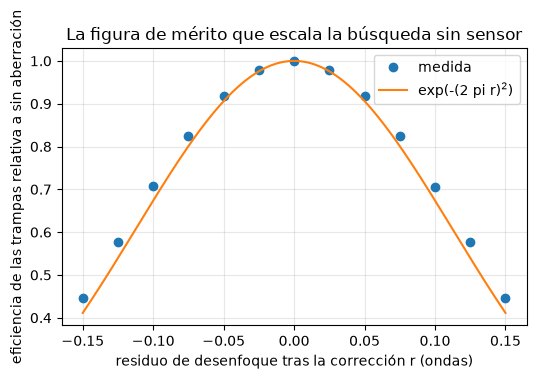

In [8]:
# la razón de eficiencia frente al residuo de un modo, con la curva de Maréchal
fine = np.linspace(-0.15, 0.15, 200)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.plot(residual, scan, "o", label="medida")
ax.plot(fine, np.exp(-(2 * np.pi * fine) ** 2), "-", label="exp(-(2 pi r)$^2$)")
ax.set_xlabel("residuo de desenfoque tras la corrección r (ondas)")
ax.set_ylabel("eficiencia de las trampas relativa a sin aberración")
ax.set_title("La figura de mérito que escala la búsqueda sin sensor")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

Los puntos medidos son simétricos respecto de cero, como lo sería una gaussiana (0,8245 en -0,075 ondas y 0,8239 en +0,075; 0,4457 y 0,4451 en los extremos de 0,15), y siguen la curva $\exp[-(2\pi r)^2]$ con diferencias de unos pocos por ciento: 0,8245 frente a 0,8009 en 0,075 ondas y 0,4457 frente a 0,4114 en 0,15. La curva medida es algo más ancha que la de Maréchal, lo que es una ventaja para la búsqueda, ya que la figura de mérito es más plana cerca del óptimo de lo que dice la estimación. La simetría significa que un modo tiene un solo máximo, de modo que una parábola de tres puntos es el modelo local correcto, y eso es todo lo que necesita la búsqueda. La figura prueba un modo, el desenfoque, con los otros siete exactos; no prueba cómo interactúan los modos cuando todos están mal, que es la razón por la que la búsqueda repite sus barridos.

### Paso 4: la búsqueda sin sensor

M14 en modo `recover` visita los modos 4 a 11. En cada uno mide la figura de mérito en $\hat c_j - \delta$, $\hat c_j$ y $\hat c_j + \delta$ con $\delta = 0{,}06$ ondas, ajusta una parábola al logaritmo y se mueve a su vértice, con el paso limitado a $2\delta$. Un barrido sobre los ocho modos cuesta 25 cuadros de cámara. Los modos no son exactamente independientes bajo un haz gaussiano y trampas fuera del eje, así que el barrido se repite hasta que la mayor actualización es menor que $10^{-4}$ ondas, o hasta agotar el presupuesto de barridos. La cámara es la emulada del pipeline. La primera corrida usa su valor por defecto, ganancias ideales y sin ruido; la segunda añade ruido gaussiano de rms 0,003 en las unidades de la intensidad de las trampas, cerca de 6 por ciento de la intensidad media de una trampa aquí.

In [9]:
# recuperación sin sensor de los modos 4 a 11 con una cámara ideal, y con una cámara que añade ruido (rms 0.003)
ideal_run = m14_zernike.run(setup, target, budget=Budget(6), rng=Rng(1), init=base.phi, mode="recover", injected=coeffs)
noisy_camera = EmulatedCamera(seed=3, gain_rms=0.0, noise_rms=0.003, rolloff=False)
noisy_run = m14_zernike.run(setup, target, budget=Budget(6), rng=Rng(1), init=base.phi, mode="recover", injected=coeffs,
                            camera=noisy_camera)
for name, run in (("cámara ideal", ideal_run), ("cámara con ruido", noisy_run)):
    for h in run.history:
        print(f"{name:18s} barrido {h['iteration']}: eficiencia {h['efficiency']:.4f}  "
              f"error rms de los coeficientes {h['coef_rms_error']:.5f}")

cámara ideal       barrido 1: eficiencia 0.7880  error rms de los coeficientes 0.01562
cámara ideal       barrido 2: eficiencia 0.7938  error rms de los coeficientes 0.00082
cámara ideal       barrido 3: eficiencia 0.7938  error rms de los coeficientes 0.00032
cámara ideal       barrido 4: eficiencia 0.7938  error rms de los coeficientes 0.00033
cámara con ruido   barrido 1: eficiencia 0.7426  error rms de los coeficientes 0.04774
cámara con ruido   barrido 2: eficiencia 0.7899  error rms de los coeficientes 0.01315
cámara con ruido   barrido 3: eficiencia 0.7924  error rms de los coeficientes 0.00815
cámara con ruido   barrido 4: eficiencia 0.7914  error rms de los coeficientes 0.01010
cámara con ruido   barrido 5: eficiencia 0.7911  error rms de los coeficientes 0.01158
cámara con ruido   barrido 6: eficiencia 0.7907  error rms de los coeficientes 0.01193


El panel izquierdo muestra el error rms de los coeficientes recuperados tras cada barrido, y el derecho los coeficientes inyectados y recuperados de la corrida con cámara ideal.

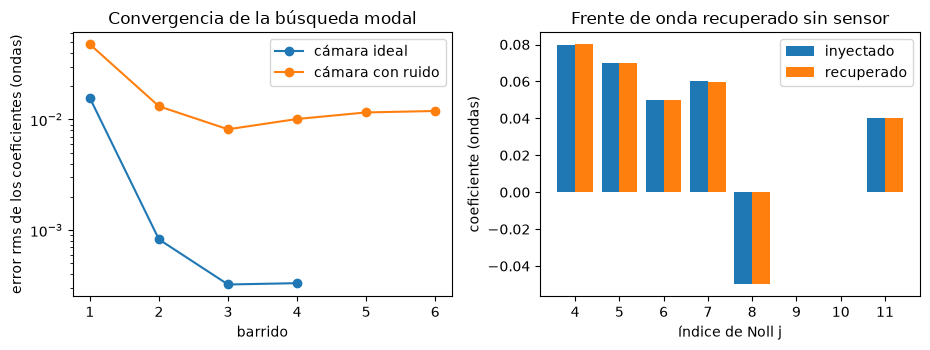

In [10]:
# izquierda: error de coeficientes por barrido; derecha: coeficientes inyectados y recuperados (cámara ideal)
fig, (a, b) = plt.subplots(1, 2, figsize=(9.4, 3.6))
for name, run in (("cámara ideal", ideal_run), ("cámara con ruido", noisy_run)):
    a.semilogy([h["iteration"] for h in run.history], [h["coef_rms_error"] for h in run.history], "o-", label=name)
a.set_xlabel("barrido")
a.set_ylabel("error rms de los coeficientes (ondas)")
a.set_title("Convergencia de la búsqueda modal")
a.legend()
slots = np.arange(len(js))
b.bar(slots - 0.2, [coeffs[j - 1] if j <= len(coeffs) else 0.0 for j in js], 0.4, label="inyectado")
b.bar(slots + 0.2, [ideal_run.meta["coefficients"][j - 1] for j in js], 0.4, label="recuperado")
b.set_xticks(slots)
b.set_xticklabels([str(j) for j in js])
b.set_xlabel("índice de Noll j")
b.set_ylabel("coeficiente (ondas)")
b.set_title("Frente de onda recuperado sin sensor")
b.legend()
plt.tight_layout()
plt.show()

Con una cámara ideal la búsqueda converge en cuatro barridos: el error rms de los coeficientes baja de 0,01562 ondas tras el primer barrido a 0,00082 tras el segundo y 0,00032 tras el tercero, donde deja de mejorar, y la eficiencia llega a 0,7938, la del sistema sin aberración, desde el barrido 2. En el panel derecho las barras no se distinguen; los dos modos que no se inyectaron, 9 y 10, se recuperan como cero. Con la cámara ruidosa el primer barrido deja un error de 0,04774 y una eficiencia de 0,7426, el segundo baja el error a 0,01315, y luego el error deja de bajar, entre 0,00815 y 0,01193 ondas, porque una parábola ajustada a tres valores ruidosos tiene un vértice que se mueve con el ruido. La eficiencia igualmente llega a 0,7907 a 0,7924, a menos de 0,4 por ciento de la ideal de 0,7938, ya que un residuo de 0,01 ondas en cada modo cuesta poca luz. La figura muestra la búsqueda con una aberración inyectada y un nivel de ruido, y una cámara con un error de ganancia por trampa añadiría un sesgo que esta corrida no tiene. También supone que la aberración es la misma en todas las trampas, que es la premisa de una corrección global.

## Resultados

**Respuesta:** Las aberraciones se describen con coeficientes de Zernike, se encuentran con una búsqueda que usa solo la luz total de las trampas, y se corrigen restando el frente de onda recuperado de la fase mostrada. Los modos son ortonormales sobre la pupila (media cuadrática 1,000, mayor producto cruzado 0,0013), de modo que el error rms del caso, 0,1466 ondas, es una suma de cuadrados, y reduce la eficiencia de las 16 trampas de 0,7938 a 0,4462 (la estimación de Maréchal de la luz, 0,4279, tiene el orden correcto pero es pesimista). La figura de mérito es una función de tipo gaussiano de cada coeficiente (una razón de 0,8245 con un residuo de 0,075 ondas frente a las 0,8009 de la exponencial), así que tres cuadros de cámara por modo ubican su óptimo: con una cámara ideal cuatro barridos, 100 cuadros, recuperan los ocho coeficientes con un error rms de 0,00033 ondas y devuelven la eficiencia a 0,7938. Con ruido de cámara de 0,003 el error se detiene cerca de 0,01193 ondas y la eficiencia es 0,7907.

Lo que el notebook no muestra es una corrección que varíe a lo largo del campo, una cámara con errores de ganancia por trampa, ni modos sobre j = 11.

## Resumen

- Un frente de onda es una suma de modos de Zernike; en la base ortonormal del pipeline su error rms es la raíz de la suma de los coeficientes al cuadrado.
- La aberración del caso C09 es de 0,1466 ondas rms y reduce la eficiencia de las trampas en 44 por ciento; la estimación de Maréchal de la pérdida es pesimista a este tamaño.
- La intensidad total de las trampas es casi una gaussiana en cada coeficiente, de modo que una parábola de tres puntos en $\ln M$ encuentra el óptimo de un modo.
- La búsqueda sin sensor de M14 recupera los ocho coeficientes a 0,00033 ondas en cuatro barridos con una cámara ideal, y a unas 0,01 ondas con una ruidosa.
- La corrección es global: supone una sola aberración para todas las trampas y no prueba nada sobre errores que dependan del campo.

## Referencias

- Noll (1976). Zernike polynomials and atmospheric turbulence. Journal of the Optical Society of America 66, 207. https://doi.org/10.1364/JOSA.66.000207
- Nogrette et al. (2014). Single-atom trapping in holographic 2D arrays of microtraps with arbitrary geometries. Physical Review X 4, 021034. https://arxiv.org/abs/1402.5329